**Attribute Information**
1) id: unique identifier
2) gender: "Male", "Female" or "Other"
3) age: age of the patient
4) hypertension: 0 if the patient doesn't have hypertension, 1 if the patient has hypertension
5) heart_disease: 0 if the patient doesn't have any heart diseases, 1 if the patient has a heart disease
6) ever_married: "No" or "Yes"
7) work_type: "children", "Govt_jov", "Never_worked", "Private" or "Self-employed"
8) Residence_type: "Rural" or "Urban"
9) avg_glucose_level: average glucose level in blood
10) bmi: body mass index
11) smoking_status: "formerly smoked", "never smoked", "smokes" or "Unknown"*
12) stroke: 1 if the patient had a stroke or 0 if not

*Note: "Unknown" in smoking_status means that the information is unavailable for this patient

In [1]:
# import dependencies
import pandas as pd
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings('ignore')

In [2]:
# load data into dataframe
data = pd.read_csv("data/healthcare-dataset-stroke-data.csv")
data.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [3]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 479.2 KB


## Data Cleaning & Preprocessing

In [4]:
# descriptive results
print(data.shape, data.duplicated().sum(), data["id"].duplicated().sum())

(5110, 12) 0 0


In [5]:
print(data.isna().sum(), (data.isna().mean()*100).round(1))

id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64 id                   0.0
gender               0.0
age                  0.0
hypertension         0.0
heart_disease        0.0
ever_married         0.0
work_type            0.0
Residence_type       0.0
avg_glucose_level    0.0
bmi                  3.9
smoking_status       0.0
stroke               0.0
dtype: float64


In [6]:
print(data["stroke"].value_counts(), data["stroke"].mean())

stroke
0    4861
1     249
Name: count, dtype: int64 0.0487279843444227


In [7]:
print(data[["age","avg_glucose_level","bmi"]].describe())

               age  avg_glucose_level          bmi
count  5110.000000        5110.000000  4909.000000
mean     43.226614         106.147677    28.893237
std      22.612647          45.283560     7.854067
min       0.080000          55.120000    10.300000
25%      25.000000          77.245000    23.500000
50%      45.000000          91.885000    28.100000
75%      61.000000         114.090000    33.100000
max      82.000000         271.740000    97.600000


In [8]:
print(data["smoking_status"].value_counts())

smoking_status
never smoked       1892
Unknown            1544
formerly smoked     885
smokes              789
Name: count, dtype: int64


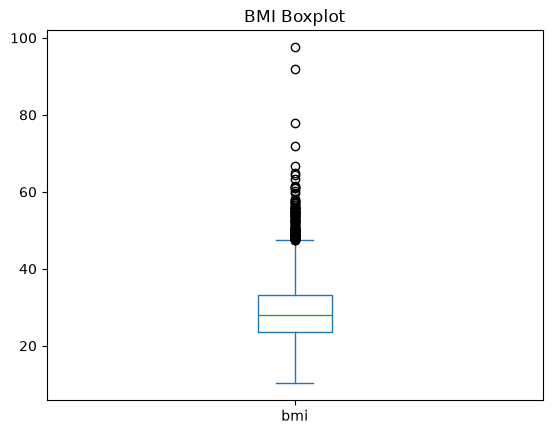

In [10]:
# bmi missing values
data['bmi'].plot(kind='box', title="BMI Boxplot")
plt.show()

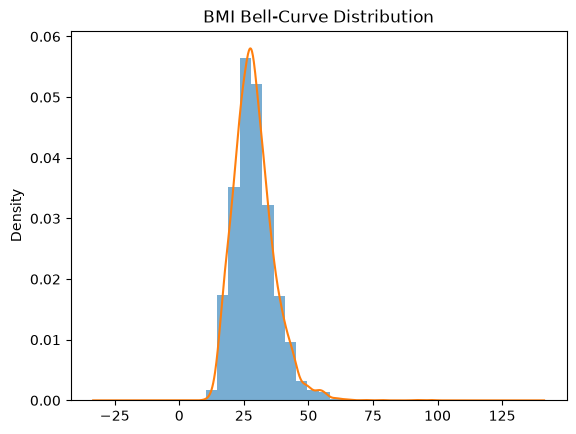

In [ ]:
# checking bmi distribution curve
ax = data['bmi'].plot.hist(density=True, bins=20, alpha=0.6)
data['bmi'].plot.kde(ax=ax)
ax.set_title("BMI Bell-Curve Distribution")
plt.show()

In [14]:
# IQR for outliers detection
Q1 = data["bmi"].quantile(0.25)
Q3 = data["bmi"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Flag outliers using bitwise OR (|) with parentheses
outliers = data[(data["bmi"] < lower_bound) | (data["bmi"] > upper_bound)]
print(f"Outlier count: {len(outliers)}")

Outlier count: 110


In [35]:
outlier_pct = len(outliers) / data["bmi"].sum() * 100
print(f"Percentage of outliers in BMI column: {outlier_pct:.4f}%")

Percentage of outliers in BMI column: 0.0776%


In [15]:
skew = data["bmi"].skew()      # Close to 0 means symmetric (between -0.5 and 0.5 is ideal)
kurt = data["bmi"].kurtosis()  # Close to 0 means normal tail thickness (Fisher's definition)
print(f"Skewness: {skew:.2f}, Kurtosis: {kurt:.2f}")

Skewness: 1.06, Kurtosis: 3.36


In [16]:
# drop id col - no duplicates
data.drop(["id"], axis=1, inplace=True)
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   gender             5110 non-null   str    
 1   age                5110 non-null   float64
 2   hypertension       5110 non-null   int64  
 3   heart_disease      5110 non-null   int64  
 4   ever_married       5110 non-null   str    
 5   work_type          5110 non-null   str    
 6   Residence_type     5110 non-null   str    
 7   avg_glucose_level  5110 non-null   float64
 8   bmi                4909 non-null   float64
 9   smoking_status     5110 non-null   str    
 10  stroke             5110 non-null   int64  
dtypes: float64(3), int64(3), str(5)
memory usage: 439.3 KB


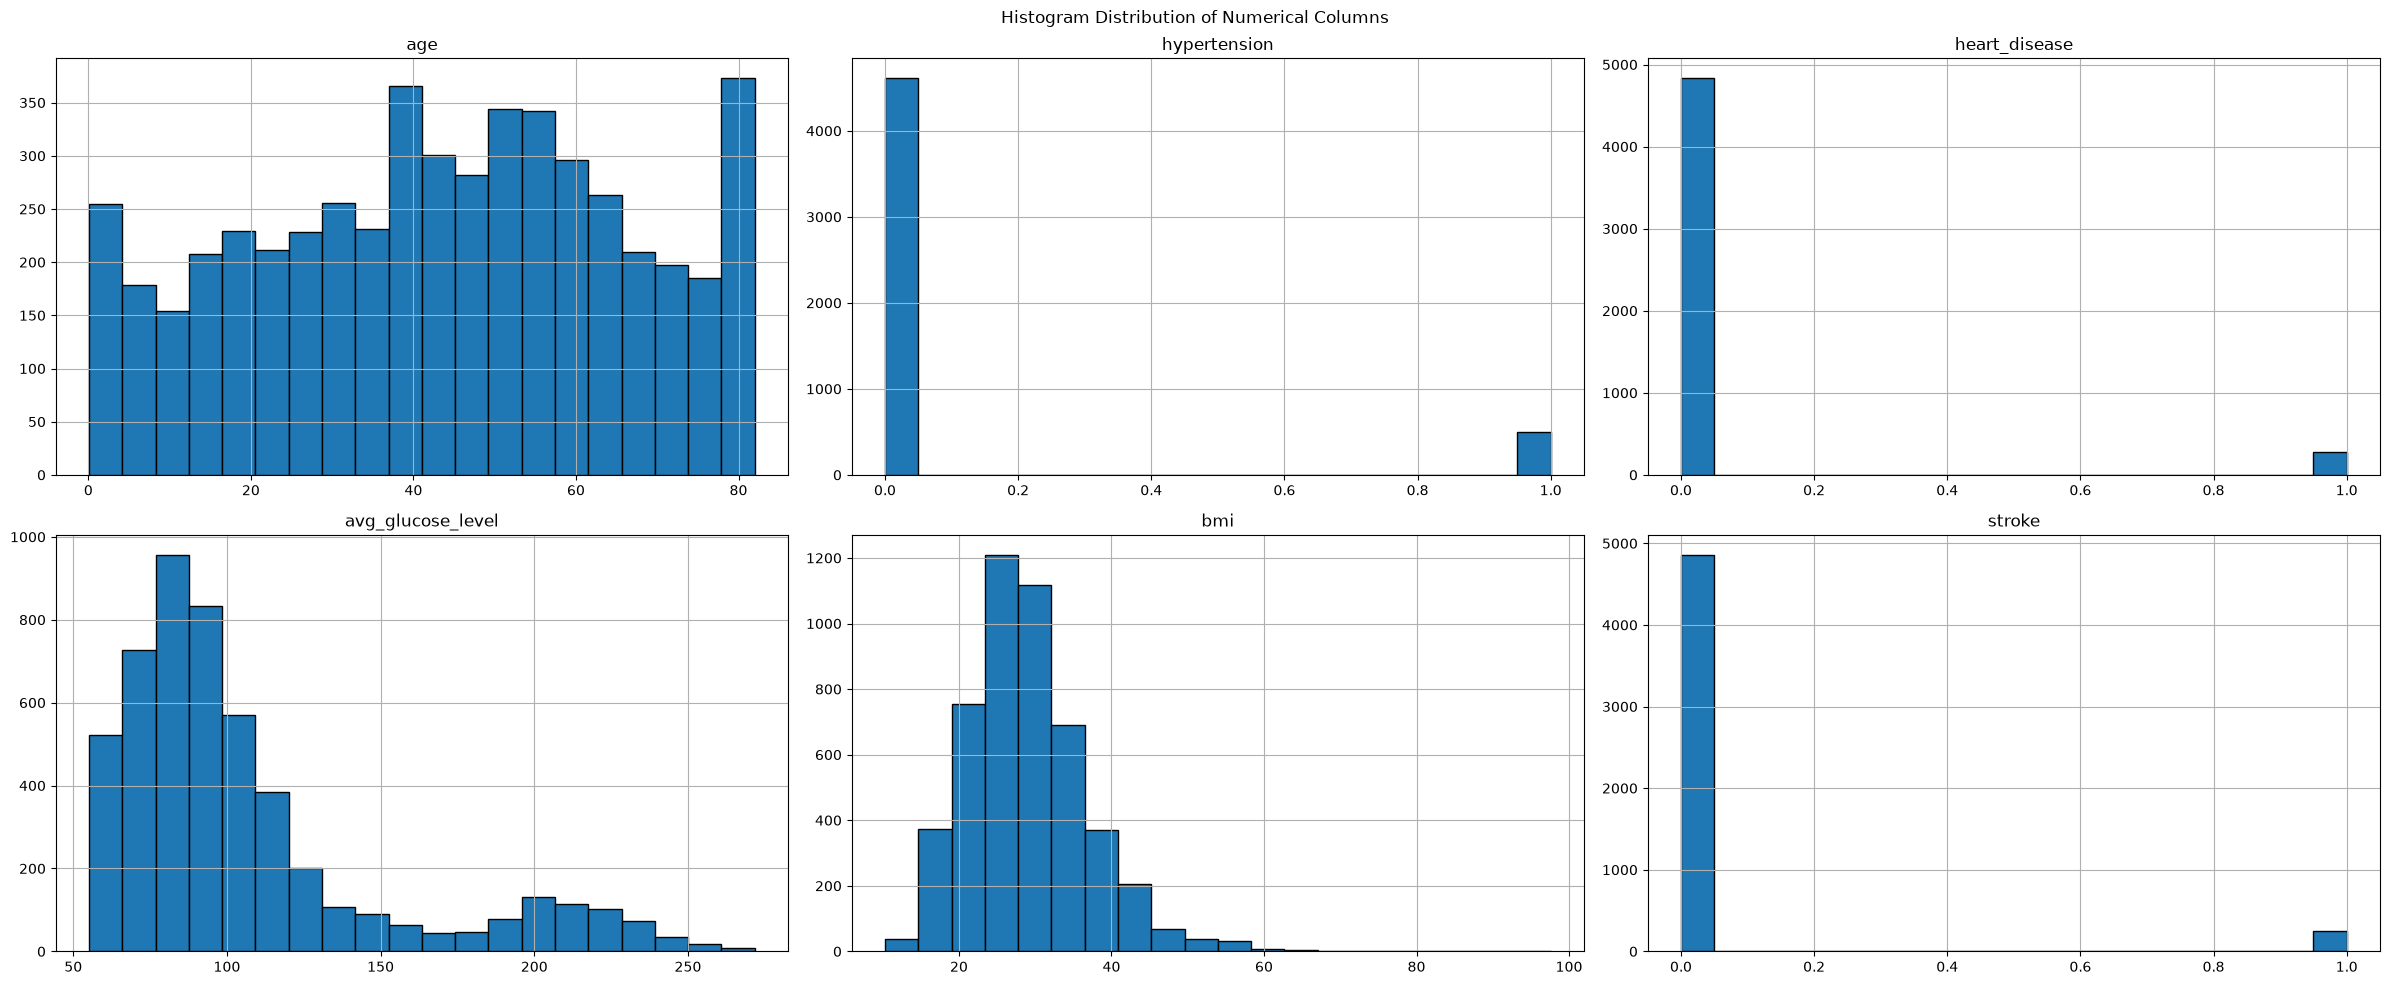

In [17]:
# entry points distribution for numerical columns
axes = data.hist(layout=(2, 3), figsize=(24, 10), bins=20, edgecolor="black")

plt.suptitle("Histogram Distribution of Numerical Columns")
plt.tight_layout()
plt.show()

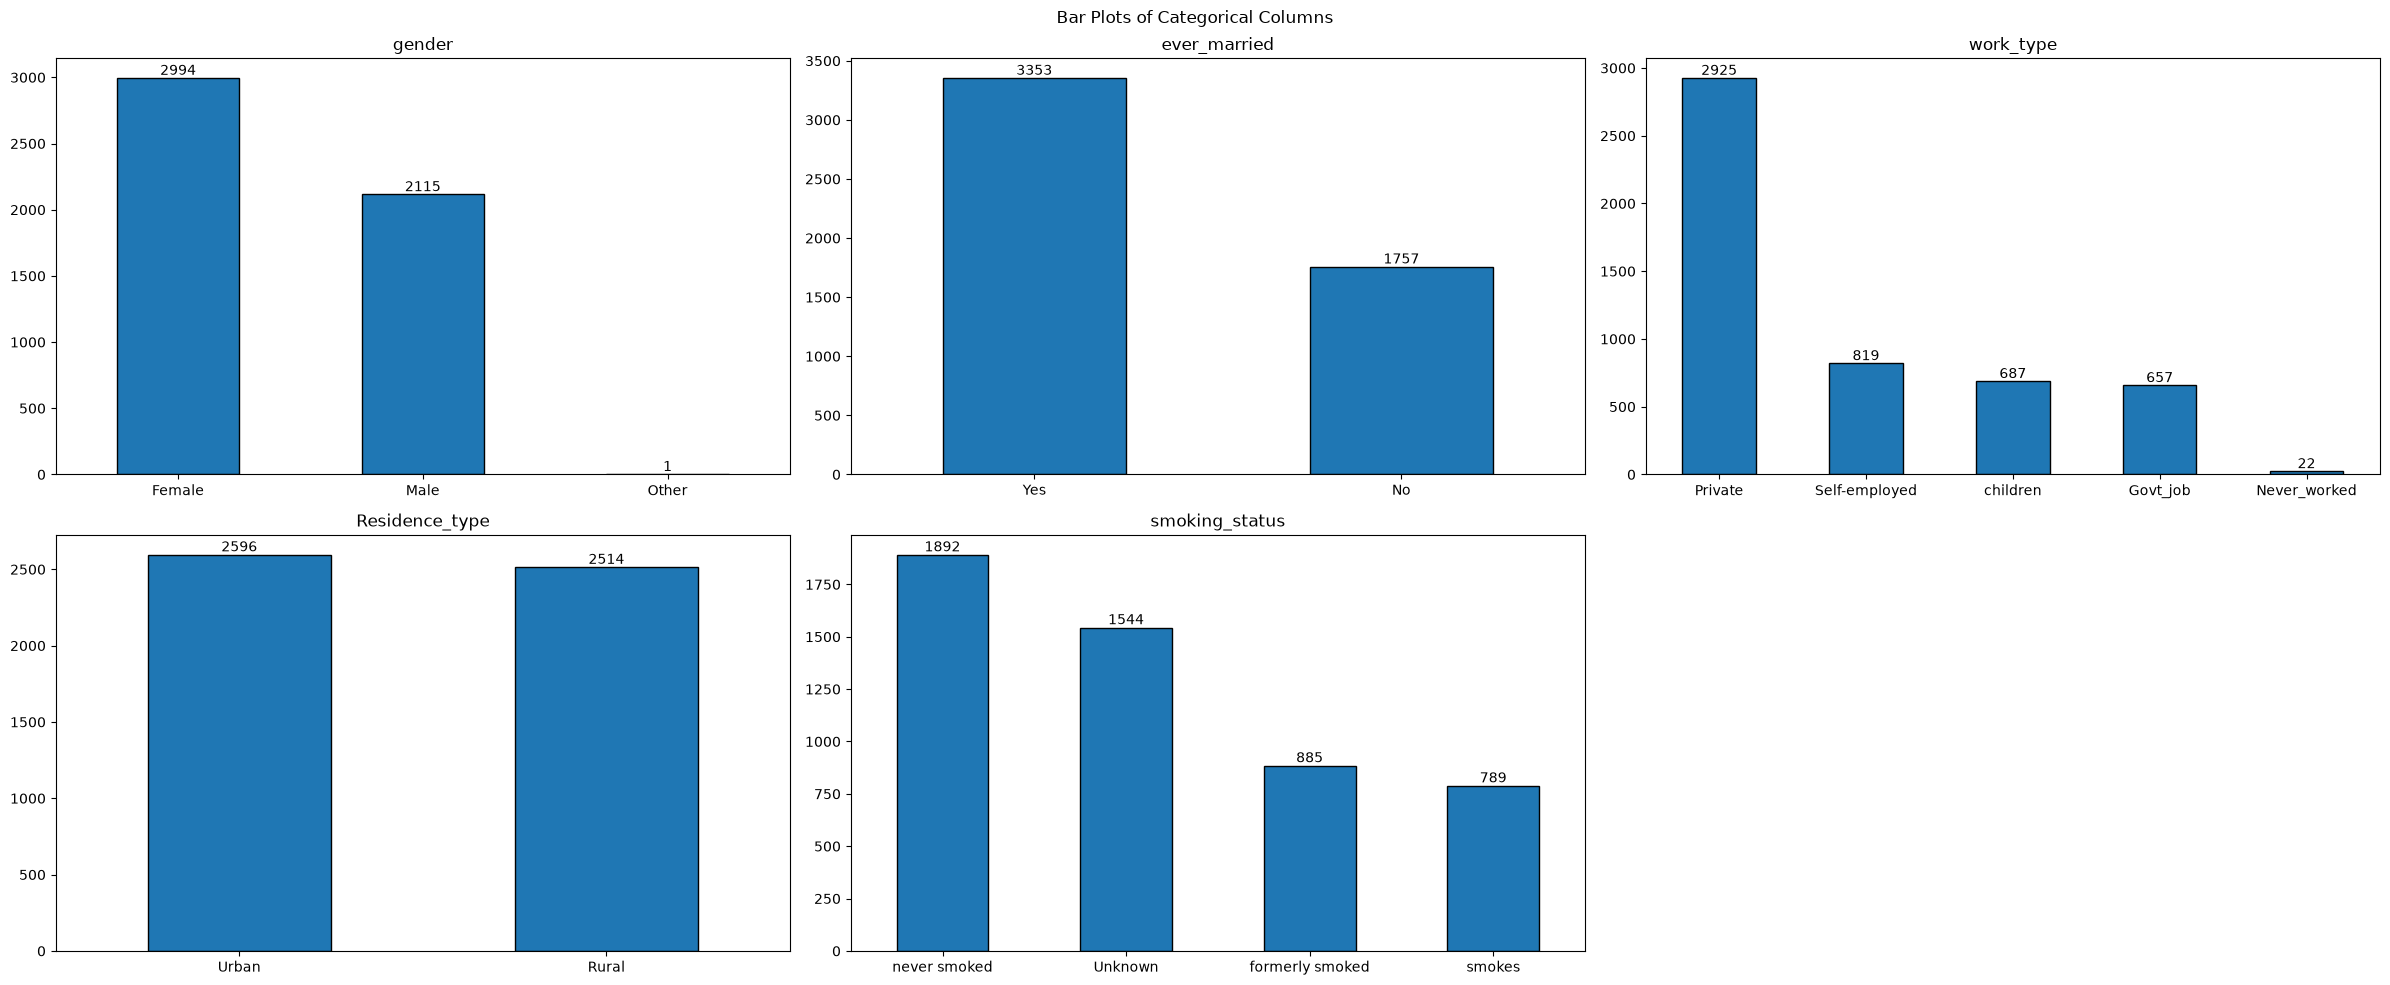

In [18]:
# handling the categorical columns
categorical_cols = ["gender",
                    "ever_married",
                    "work_type",
                    "Residence_type",
                    "smoking_status"]

fig, axs = plt.subplots(nrows=2, ncols=3, figsize=(24, 10))
axs = axs.flatten()

for ax, col in zip(axs, categorical_cols):
    data[col].value_counts().plot.bar(ax=ax, edgecolor="black", rot=0, xlabel="")
    ax.set_title(col)

    for container in ax.containers:
        ax.bar_label(container)

for ax in axs.flat[len(categorical_cols):]:
    ax.set_visible(False)

plt.suptitle("Bar Plots of Categorical Columns")
plt.tight_layout()
plt.show()


## Data Analysis

- duplicates?
- missing values?
- class imbalance?
- average age, glucose level, bmi
- categorical distributions (% per category)
- relationships between features

In [19]:
data.describe()

,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


In [20]:
# checking for duplicates
print(data.duplicated().any())

False


In [21]:
count = data["stroke"].value_counts()
percentage = data["stroke"].value_counts(normalize=True) * 100

# ratio between 0 and 1 (closer to 0 means more severe imbalance)
imbalanced_ratio = count.min() / count.max()
print(f"Imbalanced Ratio: {imbalanced_ratio:.3f}")

stroke_summary = pd.DataFrame({'Count': count, 'Percentage (%)': percentage})
stroke_summary

Imbalanced Ratio: 0.051


,Count,Percentage (%)
stroke,,
0,4861,95.127202
1,249,4.872798


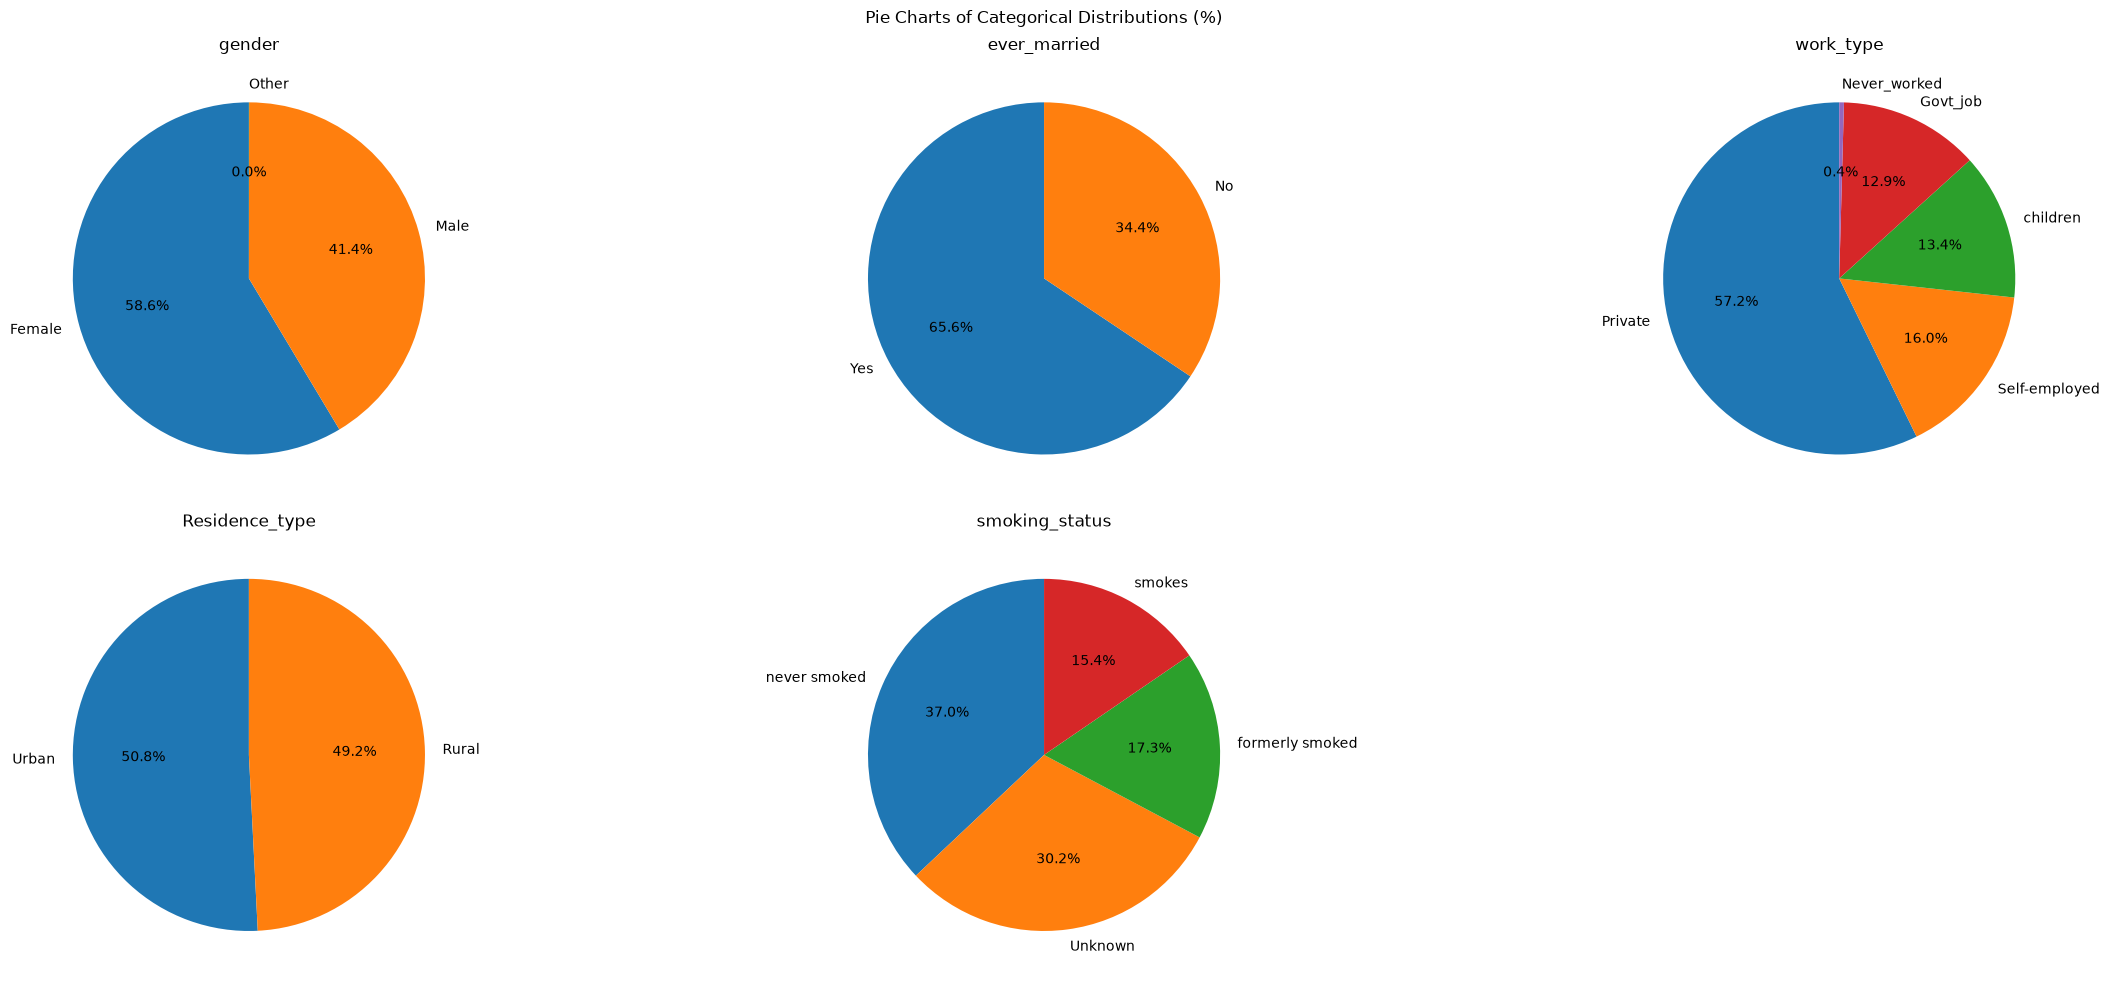

In [22]:
# categorical distributions (%)
fig, axs = plt.subplots(nrows=2, ncols=3, figsize=(24, 10))
axs = axs.flatten()

for ax, col in zip(axs, categorical_cols):
    data[col].value_counts().plot.pie(ax=ax, autopct="%1.1f%%", ylabel="", startangle=90)
    ax.set_title(col)

for ax in axs.flat[len(categorical_cols):]:
    ax.set_visible(False)

plt.suptitle("Pie Charts of Categorical Distributions (%)")
ax.axis('equal')
plt.tight_layout()
plt.show()

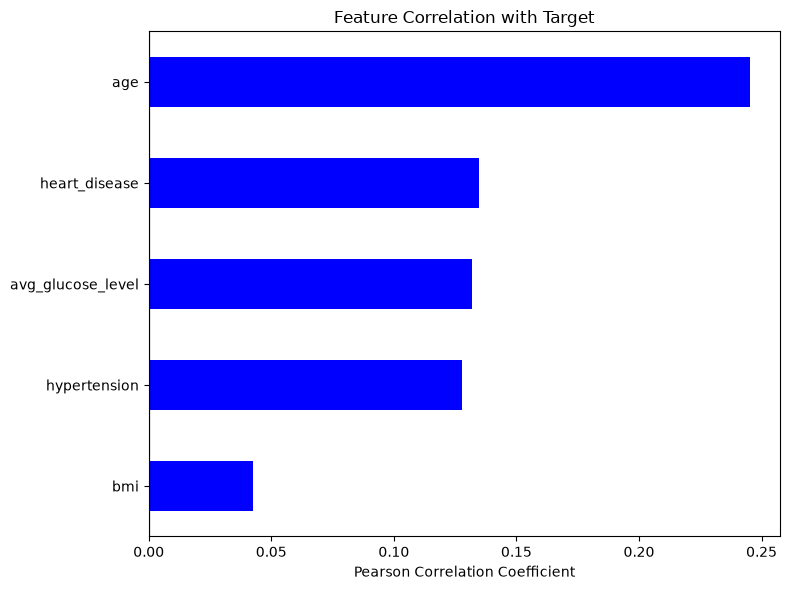

In [23]:
# compute correlation with target and drop the target's self-correlation
correlations = data.corr(numeric_only=True)['stroke'].drop('stroke').sort_values()

plt.figure(figsize=(8, 6))
correlations.plot(kind='barh', color='blue')
plt.axvline(0, color='black', linewidth=0.8)  # Reference line at 0
plt.xlabel('Pearson Correlation Coefficient')
plt.title('Feature Correlation with Target')
plt.tight_layout()
plt.show()


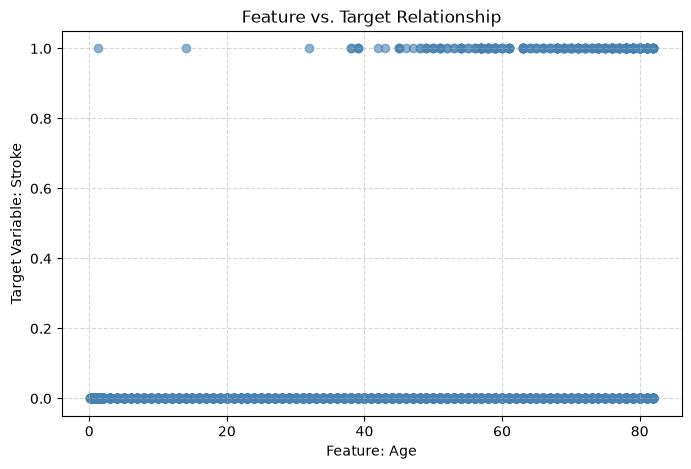

In [24]:
plt.figure(figsize=(8, 5))
plt.scatter(data["age"], data["stroke"], alpha=0.6, color='steelblue')
plt.xlabel('Feature: Age')
plt.ylabel('Target Variable: Stroke')
plt.title('Feature vs. Target Relationship')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [25]:
# Target rate by age bin
data["age_bin"] = pd.cut(data["age"], bins=[0, 18, 30, 45, 60, 75, 100])
print(data.groupby("age_bin", observed=True)["stroke"].agg(["mean", "count"]))

               mean  count
age_bin                   
(0, 18]    0.002183    916
(18, 30]   0.000000    654
(30, 45]   0.010496   1048
(45, 60]   0.049663   1188
(60, 75]   0.096544    839
(75, 100]  0.206452    465


<Axes: >

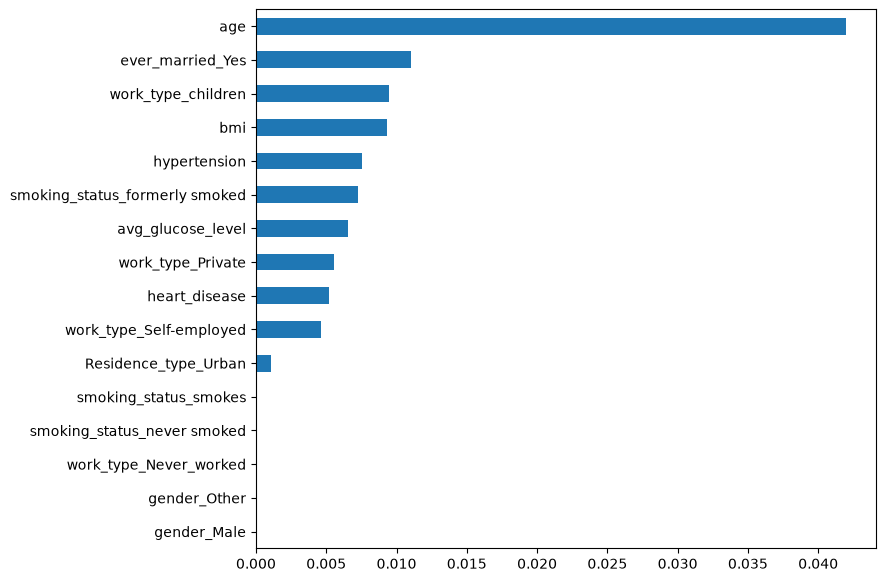

In [27]:
# mutual information (non-linear signal)
from sklearn.feature_selection import mutual_info_classif
X = pd.get_dummies(data.drop(columns=["stroke", "age_bin"]), drop_first=True).fillna(data["bmi"].median())
mutual_info = pd.Series(mutual_info_classif(X, data["stroke"], random_state=0), index=X.columns)
mutual_info.sort_values().plot.barh(figsize=(8, 7))

## Train-Test Split
1. Drop id, and separate X and y.
2. Split (stratified, with a fixed seed): train / validation / test.
3. Fit the imputer, encoder and scaler (if needed) on train only, then transform all three sets.
4. Apply any oversampling to the training set only, last.

In [ ]:
# current overview of dataset
data.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke,age_bin
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1,"(60, 75]"
1,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1,"(60, 75]"
2,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1,"(75, 100]"
3,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1,"(45, 60]"
4,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1,"(75, 100]"


## Data Preprocessing (One-Hot Encoding)

In [ ]:
# preprocessing categorical cols (one-hot encoding)
encoded = pd.get_dummies(data[categorical_cols],
                         prefix=categorical_cols)

preprocessed_data = pd.concat([data, encoded], axis=1)
preprocessed_data.drop(categorical_cols, axis=1, inplace=True)

preprocessed_data.head()

In [ ]:
# fillna bmi column - after splitting
# data is skewed, so use median to reduce variance
preprocessed_data["bmi"].fillna(preprocessed_data["bmi"].median())

In [ ]:
# saving processed data into a separate csv
preprocessed_data.to_csv("data/preprocessed_data.csv", index=False)

In [ ]:
# compute correlation with target and drop the target's self-correlation
correlations = preprocessed_data.corr(numeric_only=True)['stroke'].drop('stroke').sort_values()

plt.figure(figsize=(8, 6))
correlations.plot(kind='barh', color='blue')
plt.axvline(0, color='black', linewidth=0.8)  # Reference line at 0
plt.xlabel('Pearson Correlation Coefficient')
plt.title('Feature Correlation with Target')
plt.tight_layout()
plt.show()